# General Information
Author: Angus Slater (s4961587) 

Course: COMP3710 Pattern Recognition, The University of Queensland, 2026

Project: Improved 3D U-Net for prostate MRI segmentation (HipMRI)

# Initial Data Inspection

label-5 centre voxel: 128 125 62
axial slices containing label 5: 51 to 73 of 128


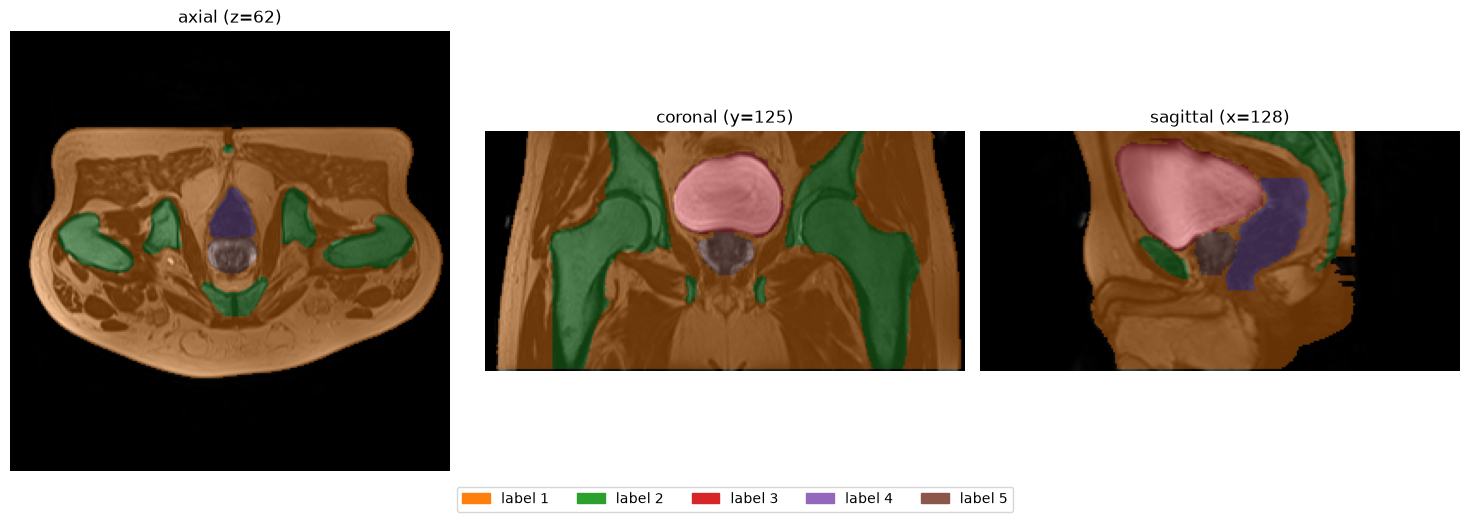

Label 1: Body
Label 2: Bone
Label 3: Bladder
Label 4: Rectum
Label 5: Prostate


In [4]:
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

d = os.path.expanduser("~/Desktop/HipMRI_sample/")
img = nib.load(d + "B040_Week0_LFOV.nii.gz").get_fdata()
lab = nib.load(d + "B040_Week0_SEMANTIC.nii.gz").get_fdata().astype(int)

# Centre the views on label 5 (what we think is the prostate)
vox = np.argwhere(lab == 5)
cx, cy, cz = vox.mean(0).astype(int)
print("label-5 centre voxel:", cx, cy, cz)
print("axial slices containing label 5:", vox[:, 2].min(), "to", vox[:, 2].max(), "of", lab.shape[2])

views = [(img[:, :, cz], lab[:, :, cz], f"axial (z={cz})"),
         (img[:, cy, :], lab[:, cy, :], f"coronal (y={cy})"),
         (img[cx, :, :], lab[cx, :, :], f"sagittal (x={cx})")]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (im, lb, title) in zip(axes, views):
    ax.imshow(im.T, cmap="gray", origin="lower")
    ax.imshow(np.ma.masked_where(lb.T == 0, lb.T), cmap="tab10", vmin=0, vmax=9,
              alpha=0.4, origin="lower")
    ax.set_title(title)
    ax.axis("off")
cmap = plt.get_cmap("tab10")
fig.legend(handles=[Patch(color=cmap(k), label=f"label {k}") for k in range(1, 6)],
           loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.06, 1, 1))
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/data_example.png", dpi=120)
plt.show()

print("Label 1: Body")
print("Label 2: Bone")
print("Label 3: Bladder")
print("Label 4: Rectum")
print("Label 5: Prostate")

In [19]:
mask = nib.load(d + "B040_Week0_LFOV.nii.gz").get_fdata()
nums = np.unique(lab, return_counts=True)[1]

sum = np.sum(nums)

print(f"Total number of voxels: {sum:,} (256*256*128)")
print(f"Num segements: {len(nums)}")

labels = ["Background", "Body", "Bone", "Bladder", "Rectum", "Prostate"]
perc = 0
for x in range(len(nums)): 
    perct = nums[x] / sum * 100
    perc += perct
    print(f"{labels[x]}: {perct:,.2f}%")

print(f"Total: {perc}%")

Total number of voxels: 8,388,608 (256*256*128)
Num segements: 6
Background: 57.06%
Body: 36.96%
Bone: 3.88%
Bladder: 1.65%
Rectum: 0.36%
Prostate: 0.10%
Total: 100.0%


Rangpur inspection showed 1 image is 256*256*144 - it will need to be cropped to 128 to fit the rest of the data. 

In [18]:
img = nib.load(d + "B040_Week0_LFOV.nii.gz")
print(img.header.get_zooms())   # voxel size in mm per axis
#print(img.affine)               # 4x4 matrix: voxel index -> mm in scanner space
#print(img.header)               # the full header

(np.float32(1.5625), np.float32(1.5625), np.float32(1.5599976))


Voxel sizes vary between scans. This one is an almost perfect 1.5625mm cube. 

Looking at Downsampled images - what the model will see (128*128*64 rather than 256*256*128)

downsampled: torch.Size([1, 128, 128, 64]) torch.Size([128, 128, 64]) prostate voxels: 1020


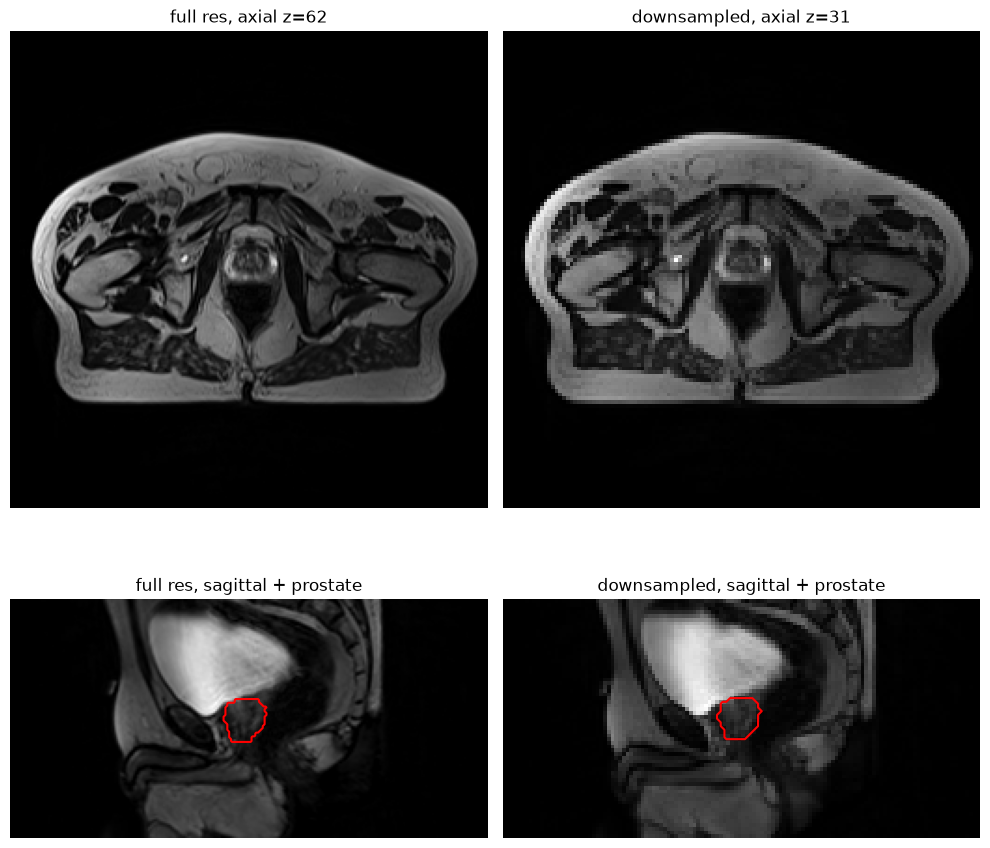

In [20]:
import matplotlib.pyplot as plt
from dataset import load_volume

d = "/Users/angusslater/Desktop/HipMRI_sample/"
img_ds, lab_ds = load_volume(d + "B040_Week0_LFOV.nii.gz", d + "B040_Week0_SEMANTIC.nii.gz")
img_full = nib.load(d + "B040_Week0_LFOV.nii.gz").get_fdata()
lab_full = nib.load(d + "B040_Week0_SEMANTIC.nii.gz").get_fdata()

print("downsampled:", img_ds.shape, lab_ds.shape, "prostate voxels:", int((lab_ds == 5).sum()))

# Prostate centre was (128, 125, 62) at full res -> (64, 62, 31) after 2x downsample.
fig, ax = plt.subplots(2, 2, figsize=(10, 10))
ax[0, 0].imshow(img_full[:, :, 62].T, cmap="gray"); ax[0, 0].set_title("full res, axial z=62")
ax[0, 1].imshow(img_ds[0, :, :, 31].T, cmap="gray"); ax[0, 1].set_title("downsampled, axial z=31")
ax[1, 0].imshow(img_full[128, :, :].T, cmap="gray", origin="lower")
ax[1, 0].contour(lab_full[128, :, :].T == 5, colors="r", origin="lower"); ax[1, 0].set_title("full res, sagittal + prostate")
ax[1, 1].imshow(img_ds[0, 64, :, :].T, cmap="gray", origin="lower")
ax[1, 1].contour(lab_ds[64, :, :].T == 5, colors="r", origin="lower"); ax[1, 1].set_title("downsampled, sagittal + prostate")
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.savefig("figures/downsample_check.png", dpi=120); plt.show()

# Analysing Baseline